# Image Classification using CNN

*   Creating deep networks using Keras
*   Training a neural network
*   Prediction and performance analysis using neural networks
*   Using pre-trained networks
*   Feature visualizations
---

# **Colaboratory environment**
By default, Colab notebooks run on CPU.
You can switch your notebook to run with GPU.

In order to obtain access to the GPU, you need to choose the tab Runtime and then select “Change runtime type” as shown in the following figure:

![Changing runtime](https://miro.medium.com/max/747/1*euE7nGZ0uJQcgvkpgvkoQg.png)

When a pop-up window appears select GPU. Ensure “Hardware accelerator” is set to GPU.

In [1]:
import os

import numpy as np
from matplotlib import pyplot as plt
from sklearn.metrics import confusion_matrix

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.backend import clear_session
from tensorflow.keras.models import Sequential
from tensorflow.keras.utils import to_categorical


try:
    import google.colab  
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    DATA_PATH = "/content/drive/MyDrive/datasets/cifar10.npz"
    MODELS_DIR = "/content/drive/MyDrive/models"
else:
    DATA_PATH = None  # local run: CIFAR-10 is downloaded through keras.datasets
    MODELS_DIR = "../outputs/models"

NUM_CLASSES = 10
CLASS_NAMES = ["airplane", "automobile", "bird", "cat", "deer",
               "dog", "frog", "horse", "ship", "truck"]

# --- GPU ---------------------------------------------------------------------
gpus = tf.config.list_physical_devices("GPU")
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)  # do not grab all VRAM at once
print("Running on Colab" if IN_COLAB else "Running locally")
print("GPUs:", gpus)

Running on Colab
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
def plot_history(histories, metrics=("loss", "accuracy"), show_val=True):
    """Plot training (and validation) curves.

    histories: dict {label: keras History}
    """
    titles = {"loss": "Cross Entropy Loss", "accuracy": "Classification Accuracy"}
    fig, axes = plt.subplots(len(metrics), 1, figsize=(8, 4 * len(metrics)))
    for ax, metric in zip(np.atleast_1d(axes), metrics):
        for label, history in histories.items():
            line, = ax.plot(history.history[metric], label=f"{label} (train)")
            if show_val and f"val_{metric}" in history.history:
                ax.plot(history.history[f"val_{metric}"], linestyle="--",
                        color=line.get_color(), label=f"{label} (val)")
        ax.set_title(titles.get(metric, metric))
        ax.set_xlabel("epoch")
        ax.legend()
    plt.tight_layout()
    plt.show()


def plot_confusion_matrix(y_true, y_pred, class_names=CLASS_NAMES, title="Confusion matrix"):
    """Plot a confusion matrix from integer labels."""
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(8, 8))
    plt.imshow(cm, cmap=plt.cm.Blues)
    thresh = cm.max() / 2.
    for i, j in np.ndindex(cm.shape):
        plt.text(j, i, cm[i, j], horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")
    ticks = np.arange(len(class_names))
    plt.xticks(ticks, class_names, rotation=45)
    plt.yticks(ticks, class_names)
    plt.title(title)
    plt.ylabel("True label")
    plt.xlabel("Predicted label")
    plt.colorbar()
    plt.tight_layout()
    plt.show()
    return cm


def predict_labels(model, x):
    """Return the predicted class index for every sample."""
    return np.argmax(model.predict(x), axis=1)


def evaluate_model(model, x, y):
    """Print and return test loss / accuracy (y one-hot)."""
    test_loss, test_acc = model.evaluate(x, y)
    print("Test accuracy:", test_acc)
    print("Test loss:", test_loss)
    return test_loss, test_acc

In [3]:
# Load CIFAR-10 
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    data = np.load(DATA_PATH)
    x_train, y_train = data["x_train"], data["y_train"]
    x_test, y_test = data["x_test"], data["y_test"]
else:
    from tensorflow.keras.datasets import cifar10
    (x_train, y_train), (x_test, y_test) = cifar10.load_data()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


(50000, 32, 32, 3)
4
uint8
(10000, 32, 32, 3)
(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8), array([5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000, 5000]))


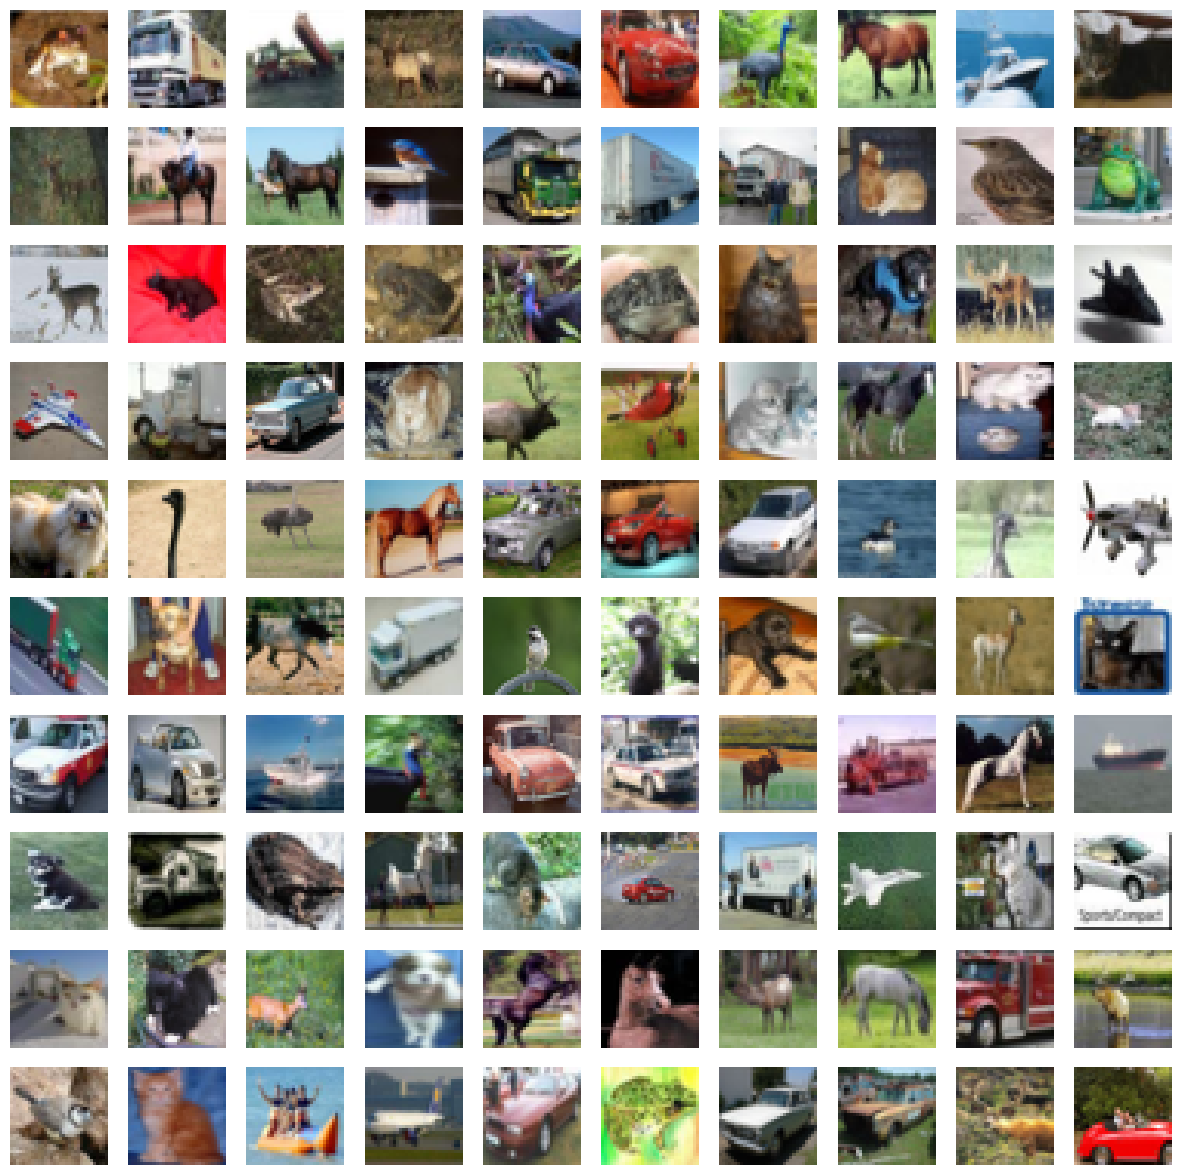

In [4]:
print(x_train.shape)
print(x_train.ndim)
print(x_train.dtype)

print(x_test.shape)
print(np.unique(y_train, return_counts=True))

fig, axes = plt.subplots(ncols=10, nrows=10, figsize=(15, 15))
for i in range(10):
    for j in range(10):
        axes[i][j].imshow(x_train[(i * 10) + j])
        axes[i][j].axis("off")
plt.show()

In [5]:
# Preprocessing (run ONCE): scale to [0, 1] and one-hot encode the labels.
# Integer labels are kept in *_labels for the confusion matrices.
x_train = x_train.astype("float32") / 255
x_test = x_test.astype("float32") / 255

y_train_labels = y_train.ravel()
y_test_labels = y_test.ravel()
y_train = to_categorical(y_train_labels, num_classes=NUM_CLASSES)
y_test = to_categorical(y_test_labels, num_classes=NUM_CLASSES)

print(x_train.shape, y_train.shape)
print(x_test.shape, y_test.shape)

(50000, 32, 32, 3) (50000, 10)
(10000, 32, 32, 3) (10000, 10)


## Define the following model

**For the convolutional front-end, start with a single convolutional layer with a small filter size (3,3) and a modest number of filters (32) followed by a max pooling layer. Use the input as (32,32,3). The filter maps can then be flattened to provide features to the classifier. Use a dense layer with 100 units before the classification layer (which is also a dense layer with softmax activation).**

In [9]:
clear_session()

model = Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, (3, 3), activation="relu", kernel_initializer="he_uniform"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(100, activation="relu", kernel_initializer="he_uniform"),
    layers.Dense(NUM_CLASSES, activation="softmax"),
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 7200)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │       720,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 722,006 (2.75 MB)

 Trainable params: 722,006 (2.75 MB)

 Non-trainable params: 0 (0.00 B)

*   Compile the model using categorical_crossentropy loss, SGD optimizer and use 'accuracy' as the metric.
*   Use the above defined model to train CIFAR-10 and train the model for 512 epochs with a batch size of 32.

In [10]:
# solution
model.compile(loss="categorical_crossentropy", optimizer="sgd", metrics=["accuracy"])
history_shallow = model.fit(x_train, y_train, epochs=50, batch_size=32, validation_split=0.1)
os.makedirs(MODELS_DIR, exist_ok=True)
model.save(os.path.join(MODELS_DIR, "shallow_cifar10.keras"))

Epoch 1/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 15s 6ms/step - accuracy: 0.3614 - loss: 1.7830 - val_accuracy: 0.3966 - val_loss: 1.6431
Epoch 2/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.4935 - loss: 1.4349 - val_accuracy: 0.4930 - val_loss: 1.4321
Epoch 3/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.5413 - loss: 1.3019 - val_accuracy: 0.4776 - val_loss: 1.4668
Epoch 4/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.5733 - loss: 1.2131 - val_accuracy: 0.5292 - val_loss: 1.2999
Epoch 5/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6006 - loss: 1.1453 - val_accuracy: 0.5650 - val_loss: 1.2206
Epoch 6/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6214 - loss: 1.0852 - val_accuracy: 0.5930 - val_loss: 1.1667
Epoch 7/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6422 - loss: 1.0315 - val_accuracy: 0.5844 - val_loss: 1.1926
Epoch 8/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6600 - loss: 0.9818 -

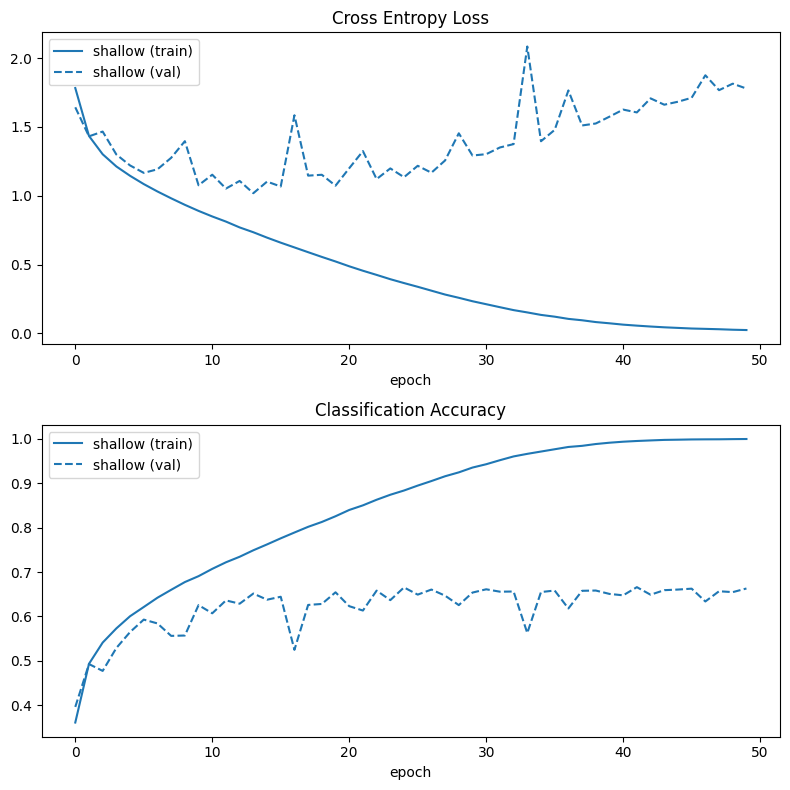

In [ ]:
plot_history({"shallow": history_shallow})

## Defining Deeper Architectures: VGG Models

*   Define a deeper model architecture for CIFAR-10 dataset and train the new model for 512 epochs with a batch size of 32. We will use VGG model as the architecture.

**Stack two convolutional layers with 32 filters, each of 3 x 3. Use a max pooling layer and next flatten the output of the previous layer and add a dense layer with 128 units before the classification layer. For all the layers, use ReLU activation function. Use same padding for the layers to ensure that the height and width of each layer output matches the input**


In [ ]:
# solution
clear_session()

deeper_model = Sequential([
    keras.Input(shape=(32, 32, 3)),
    layers.Conv2D(32, (3, 3), activation="relu", kernel_initializer="he_uniform", padding="same"),
    layers.Conv2D(32, (3, 3), activation="relu", kernel_initializer="he_uniform", padding="same"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation="relu", kernel_initializer="he_uniform"),
    layers.Dense(NUM_CLASSES, activation="softmax"),
])
deeper_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     1,048,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,060,138 (4.04 MB)

 Trainable params: 1,060,138 (4.04 MB)

 Non-trainable params: 0 (0.00 B)

*   Compile the model using categorical_crossentropy loss, SGD optimizer and use 'accuracy' as the metric.
*   Use the above defined model to train CIFAR-10 and train the model for 512 epochs with a batch size of 32.

In [ ]:
# solution
deeper_model.compile(loss="categorical_crossentropy", optimizer="sgd", metrics=["accuracy"])
history_deeper = deeper_model.fit(x_train, y_train, epochs=50, batch_size=32, validation_split=0.1)
deeper_model.save(os.path.join(MODELS_DIR, "deeper_cifar10.keras"))

Epoch 1/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 14s 7ms/step - accuracy: 0.3892 - loss: 1.7060 - val_accuracy: 0.4634 - val_loss: 1.4892
Epoch 2/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.5198 - loss: 1.3545 - val_accuracy: 0.5046 - val_loss: 1.4052
Epoch 3/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.5819 - loss: 1.1882 - val_accuracy: 0.5396 - val_loss: 1.3070
Epoch 4/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6220 - loss: 1.0818 - val_accuracy: 0.6012 - val_loss: 1.1322
Epoch 5/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6530 - loss: 0.9916 - val_accuracy: 0.6396 - val_loss: 1.0467
Epoch 6/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6800 - loss: 0.9126 - val_accuracy: 0.6338 - val_loss: 1.0419
Epoch 7/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.7074 - loss: 0.8398 - val_accuracy: 0.6062 - val_loss: 1.1941
Epoch 8/50
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.7326 - loss: 0.7701 -

*   Compare the performance of both the models by plotting the loss and accuracy curves of both the training steps. Does the deeper model perform better?


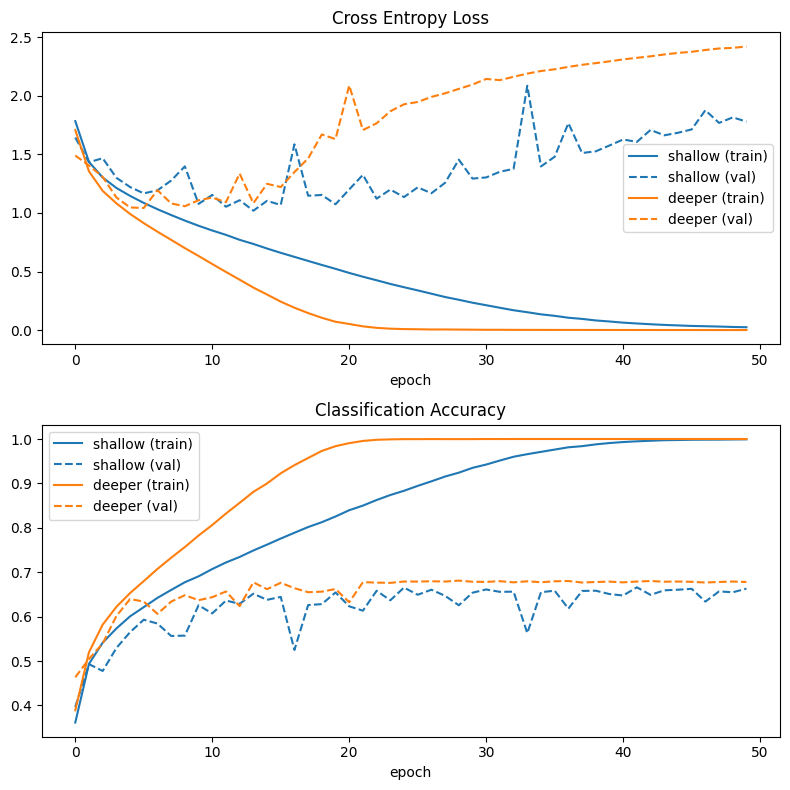

In [ ]:
# solution
plot_history({"shallow": history_shallow, "deeper": history_deeper})

*   Use predict function to predict the output for the test split
*   Plot the confusion matrix for the new model and comment on the class confusions.


313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step
(10000,) (10000,)


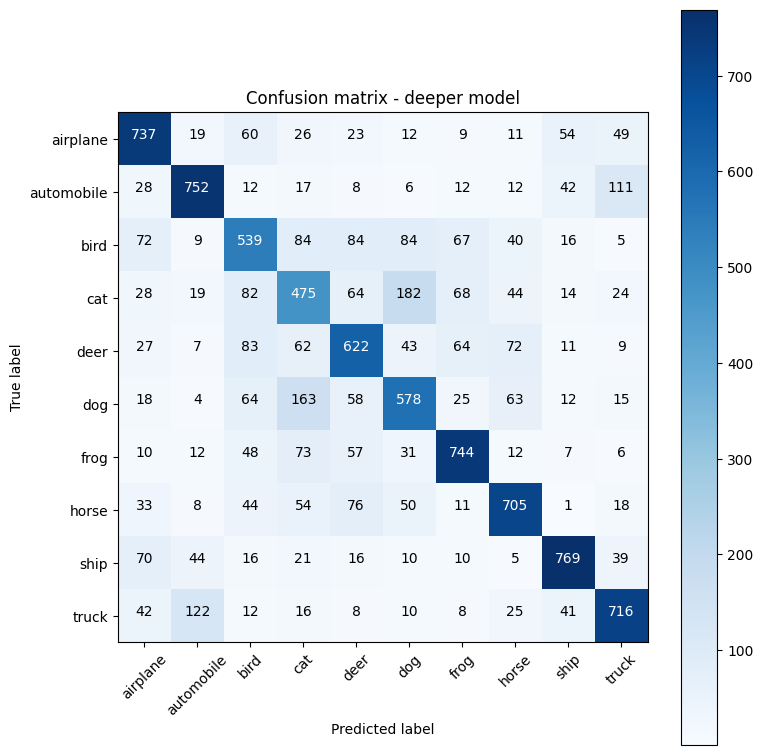

In [ ]:
# solution
y_pred_deeper = predict_labels(deeper_model, x_test)
print(y_test_labels.shape, y_pred_deeper.shape)
cm_deeper = plot_confusion_matrix(y_test_labels, y_pred_deeper, title="Confusion matrix - deeper model")

*    Print the test accuracy for the trained model.

In [ ]:
# solution
evaluate_model(deeper_model, x_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.6637 - loss: 2.5767
Test accuracy: 0.6636999845504761
Test loss: 2.5767292976379395


(2.5767292976379395, 0.6636999845504761)

## Define the complete VGG architecture.

**Stack two convolutional layers with 64 filters, each of 3 x 3 followed by max pooling layer. Stack two more convolutional layers with 128 filters, each of 3 x 3, followed by max pooling, follwed by two more convolutional layers with 256 filters, each of 3 x 3, followed by max pooling. Flatten the output of the previous layer and add a dense layer with 128 units before the classification layer. For all the layers, use ReLU activation function. Use same padding for the layers to ensure that the height and width of each layer output matches the input**

*   Change the size of input to 64 x 64.

In [ ]:
from keras.backend import clear_session
clear_session()

In [ ]:
vgg16 = keras.Sequential([
    keras.Input(shape = (32,32,3)),
    keras.layers.Resizing(64,64),
    keras.layers.RandomFlip("horizontal"),
    keras.layers.RandomTranslation(0.1, 0.1),
    keras.layers.RandomRotation(0.05),
    keras.layers.Conv2D(64, kernel_size=3, strides=(1,1), padding = "same", activation="relu"),#(64,64,64)
    keras.layers.Conv2D(64, kernel_size=3, strides=(1,1), padding = "same", activation="relu"),#(64,64,64)
    keras.layers.MaxPool2D(2),#(32,32,64)
    keras.layers.Dropout(0.2),
    keras.layers.Conv2D(128, kernel_size=3, strides=(1,1), padding = "same", activation="relu"),#(32,32,128)
    keras.layers.Conv2D(128, kernel_size=3, strides=(1,1), padding = "same", activation="relu"),#(32,32,128)
    keras.layers.MaxPool2D(2),#(16,16,128),
    keras.layers.Dropout(0.3),
    keras.layers.Conv2D(256, kernel_size=3, strides=(1,1), padding = "same", activation="relu"),#(16,16,256)
    keras.layers.Conv2D(256, kernel_size=3, strides=(1,1), padding = "same", activation="relu"),#(16,16,256)
    keras.layers.Conv2D(256, kernel_size=3, strides=(1,1), padding = "same", activation="relu"),#(16,16,256)
    keras.layers.MaxPool2D(2),#(8,8,256)
    keras.layers.Dropout(0.4),
    keras.layers.Flatten(),#(16384,)
    keras.layers.Dense(128, activation= "relu"),
    keras.layers.Dropout(0.5),
    keras.layers.Dense(10, activation= "softmax") 
])
vgg16.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ resizing (Resizing)             │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 64, 64, 3)      │             0 │
│ (RandomTranslation)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 64, 64, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 32, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 16, 16, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     2,097,280 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,834,058 (14.63 MB)

 Trainable params: 3,834,058 (14.63 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# solution
vgg16.compile(loss="categorical_crossentropy", optimizer="adam", metrics=["accuracy"])
history_vgg = vgg16.fit(x_train, y_train, epochs=50, batch_size=128, validation_split=0.1)

Epoch 1/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 33s 72ms/step - accuracy: 0.2476 - loss: 2.0134 - val_accuracy: 0.4200 - val_loss: 1.5961
Epoch 2/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 22s 63ms/step - accuracy: 0.3984 - loss: 1.6490 - val_accuracy: 0.4952 - val_loss: 1.3924
Epoch 3/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 22s 62ms/step - accuracy: 0.4529 - loss: 1.4969 - val_accuracy: 0.5474 - val_loss: 1.2365
Epoch 4/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 22s 62ms/step - accuracy: 0.5046 - loss: 1.3682 - val_accuracy: 0.6146 - val_loss: 1.0693
Epoch 5/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 22s 62ms/step - accuracy: 0.5483 - loss: 1.2651 - val_accuracy: 0.6556 - val_loss: 0.9627
Epoch 6/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 22s 62ms/step - accuracy: 0.5751 - loss: 1.1959 - val_accuracy: 0.6802 - val_loss: 0.9000
Epoch 7/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 22s 62ms/step - accuracy: 0.6036 - loss: 1.1231 - val_accuracy: 0.7048 - val_loss: 0.8176
Epoch 8/50
352/352 ━━━━━━━━━━━━━━━━━━━━ 22s 62ms/step - accuracy: 0.6185 - loss: 1.0853 - 

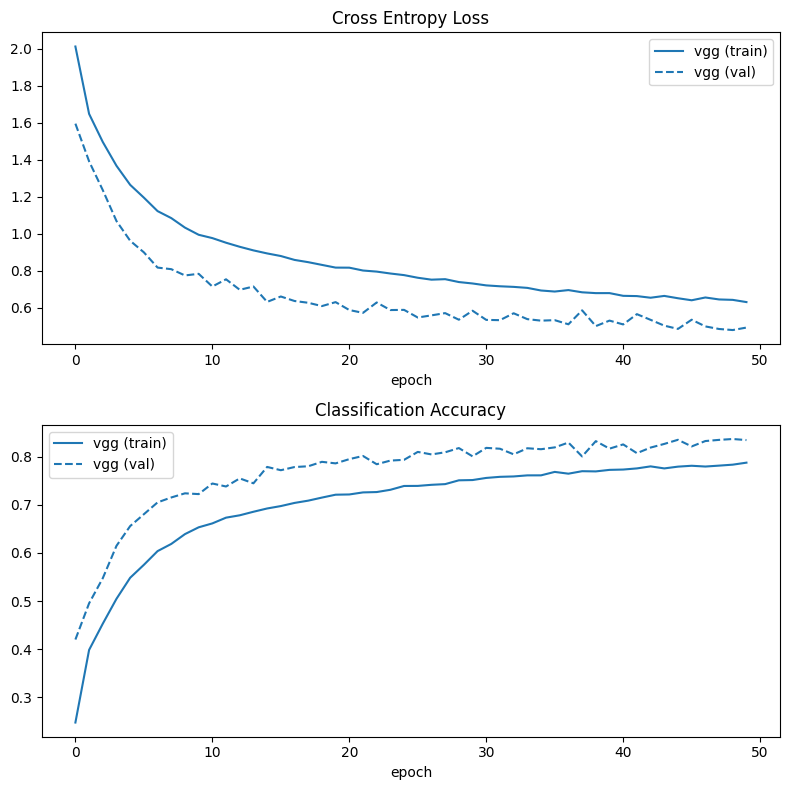

In [ ]:
# solution
plot_history({"vgg": history_vgg})

In [ ]:
# solution
evaluate_model(vgg16, x_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8316 - loss: 0.5218
Test accuracy: 0.83160001039505
Test loss: 0.521775484085083


(0.521775484085083, 0.83160001039505)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


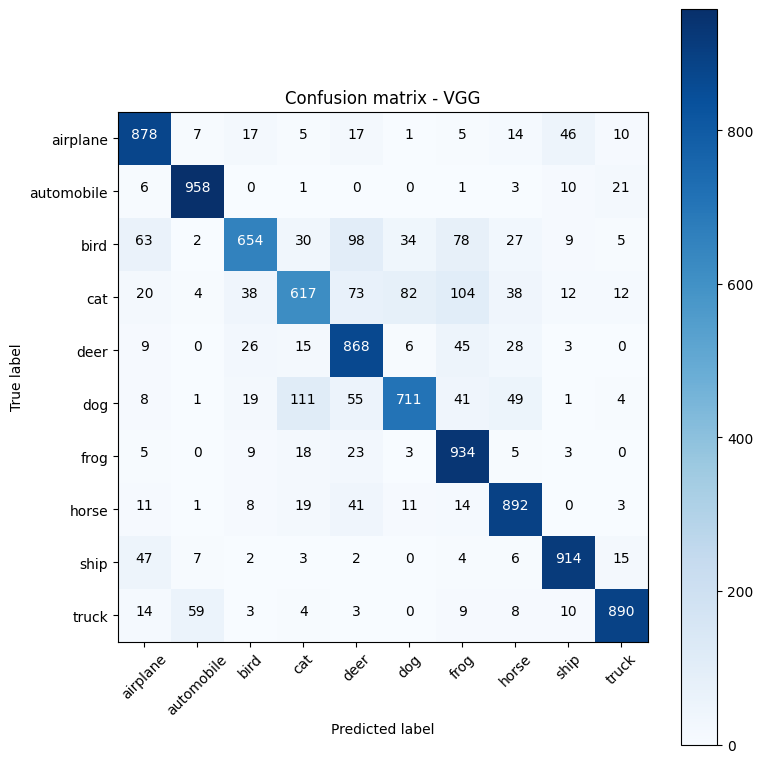

In [ ]:
y_pred_vgg = predict_labels(vgg16, x_test)
cm_vgg = plot_confusion_matrix(y_test_labels, y_pred_vgg, title="Confusion matrix - VGG")

*   Compile the model using categorical_crossentropy loss, SGD optimizer and use 'accuracy' as the metric.
*   Use the above defined model to train CIFAR-10 and train the model for 100 epochs with a batch size of 32.
*   Predict the output for the test split and plot the confusion matrix for the new model and comment on the class confusions.

# Understanding deep networks

*   What is the use of activation functions in network? Why is it needed?
*   We have used softmax activation function in the exercise. There are other activation functions available too. What is the difference between sigmoid activation and softmax activation?
*   What is the difference between categorical crossentropy and binary crossentropy loss?

In [ ]:
os.makedirs(MODELS_DIR, exist_ok=True)
vgg16.save(os.path.join(MODELS_DIR, "vgg16_cifar10.keras"))

# Transfer Learning

It is not always necessary to train models from scratch. We can use the knowledge of networks trained on other tasks to learn the task at hand. In this exercise, we will explore the use of pre-trained weights and train on the CIFAR-10 dataset.

*   Create a base imagenet pretrained InceptionV3 model.
    *    Hint: Use tf.keras.applications to create the model
    *    Pay attention to the include_top parameter.
*    Add a global average pooling layer, followed by a fully-connected layer with 1024 neurons and then the classification layer.
*   Train the model by freezing the base model. Train only the newly added layers.
    *    Hint: Every layer has an attribute called 'trainable'
*   Compile the model and train the model for a few epochs only.

In [ ]:
from keras.backend import clear_session
clear_session()

In [6]:
# solution
from keras.applications import InceptionV3
from tensorflow.keras.optimizers import Adam
from keras.layers import Dense, GlobalAveragePooling2D
from keras.models import Model

inception_model = InceptionV3(
    include_top=False,
    weights="imagenet",
    input_tensor=None,
    input_shape=None,
    pooling=None,
    classes=1000,
    classifier_activation="softmax",
    name="inception_v3",
)

# freeze the base model
for layer in inception_model.layers:
    layer.trainable = False

x = inception_model.output
x = GlobalAveragePooling2D(name="global_avg_pool")(x)
x = Dense(1024, activation='relu', name="custom_dense")(x)
predictions = Dense(10, activation='softmax', name="predictions")(x)

model = Model(inputs=inception_model.input, outputs=predictions)

learning_rate = 0.001
model.compile(optimizer=Adam(learning_rate=learning_rate), loss='categorical_crossentropy', metrics=['accuracy'])
# model.summary()

87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


In [7]:
# resize all images in x_train to 64x64, the shape of x_train is (50000, 32, 32, 3)
from skimage import transform
x_train_small = np.array([transform.resize(img, (128, 128, 3), preserve_range=True, anti_aliasing=True) for img in x_train[:1000]])

In [8]:
# solution
y_train_small = y_train[:1000]
model.fit(x_train_small, y_train_small, epochs=10, batch_size=32, validation_split=0.1)

Epoch 1/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 51s 959ms/step - accuracy: 0.3700 - loss: 3.8776 - val_accuracy: 0.4800 - val_loss: 1.3608
Epoch 2/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.7500 - loss: 0.7579 - val_accuracy: 0.6100 - val_loss: 1.0498
Epoch 3/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8778 - loss: 0.3892 - val_accuracy: 0.6200 - val_loss: 1.1762
Epoch 4/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9244 - loss: 0.2734 - val_accuracy: 0.6200 - val_loss: 1.0928
Epoch 5/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9811 - loss: 0.1304 - val_accuracy: 0.6200 - val_loss: 1.2015
Epoch 6/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9933 - loss: 0.0725 - val_accuracy: 0.6400 - val_loss: 1.1489
Epoch 7/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 1.0000 - loss: 0.0361 - val_accuracy: 0.6000 - val_loss: 1.0698
Epoch 8/10
29/29 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 1.0000 - loss: 0.0275 - val_accuracy: 0.6400 -

*    Freeze the bottom layers and unfreeze the base layers.
*    Compile and train the classifier with a very low learning rate (0.0001)

In [9]:
for layer in inception_model.layers:
  layer.trainable = True
for layer in model.layers:
  if layer.name in ['custom_dense', 'predictions']:
    layer.trainable = False
model.compile(optimizer=Adam(learning_rate=0.0001), loss='categorical_crossentropy', metrics=['accuracy'])
#model.summary()
model.fit(x_train_small, y_train_small, epochs=5, batch_size=32, validation_split=0.1)
model.save(os.path.join(MODELS_DIR, "inceptionv3_finetuned_cifar10.keras"))

Epoch 1/5
29/29 ━━━━━━━━━━━━━━━━━━━━ 143s 2s/step - accuracy: 0.5067 - loss: 1.5108 - val_accuracy: 0.7100 - val_loss: 1.2784
Epoch 2/5
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.8167 - loss: 0.6767 - val_accuracy: 0.6700 - val_loss: 1.1632
Epoch 3/5
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.9189 - loss: 0.3404 - val_accuracy: 0.6500 - val_loss: 1.1718
Epoch 4/5
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - accuracy: 0.9622 - loss: 0.1857 - val_accuracy: 0.7100 - val_loss: 1.0433
Epoch 5/5
29/29 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.9711 - loss: 0.1442 - val_accuracy: 0.7000 - val_loss: 1.0795


*    When do we train models from scratch? What are the potential issues in training models from scratch?

*    Why do we use pre-trained weights?
*    What is the difference between using random initialization and using weights from a pre-trained model?

# Extracting features from Deep Networks

It is quite possible to extract features (similar to SIFT or ORB) from different layers of deep network.

*   Load ResNet50 model with imagenet weights and check the summary of the model
*   Create a model to extract features from the 'avg_pool' layer.
*   Extract features from the layer for all the train images.
*   Use the extracted features to train a SVM classifier.
    *    Use GridSearchCV and SVC to perform the classification

In [10]:
# solution
from tensorflow.keras.applications import ResNet50
from tensorflow.keras import Model

model = ResNet50()
# model.summary()

102967424/102967424 ━━━━━━━━━━━━━━━━━━━━ 6s 0us/step


*    Evaluate the trained SVM model using the test set
*    Calculate the accuracy score and confusion matrix

In [11]:
# solution
from skimage import transform
from tensorflow.keras.applications.resnet50 import preprocess_input

extract = Model(model.inputs, model.get_layer('avg_pool').output)

dl_feature_descriptors = []

N = 150
# get N examples per class
x_train_stratified = np.empty((10*N,)+x_train[0].shape)
y_train_stratified = np.empty((10*N,)+y_train[0].shape)
for cl in range(10):
  x_train_stratified[cl*N:(cl+1)*N] = x_train[np.where(np.argmax(y_train, axis=1) == cl)[0][:N]]
  y_train_stratified[cl*N:(cl+1)*N] = y_train[np.where(np.argmax(y_train, axis=1) == cl)[0][:N]]
print(np.unique(np.argmax(y_train_stratified, axis=1), return_counts=True))

# resize to 224x224x3
x_train_stratified = np.array([
  transform.resize(img, (224, 224, 3), preserve_range=True, anti_aliasing=True) 
  for img in x_train_stratified
  ])
batch_size = 32
for i in range(0, len(x_train_stratified), batch_size):
  example = x_train_stratified[i:i+batch_size]
  desc = extract.predict(preprocess_input(example * 255))  # ResNet50 expects its own [0,255] preprocessing
  dl_feature_descriptors.append(desc)

dl_feature_descriptors = np.concatenate(dl_feature_descriptors, axis=0)
print(dl_feature_descriptors.shape)

(array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([150, 150, 150, 150, 150, 150, 150, 150, 150, 150]))
1/1 ━━━━━━━━━━━━━━━━━━━━ 9s 9s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 8

{'C': 10, 'kernel': 'linear'}
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step
SVM test accuracy: 0.344


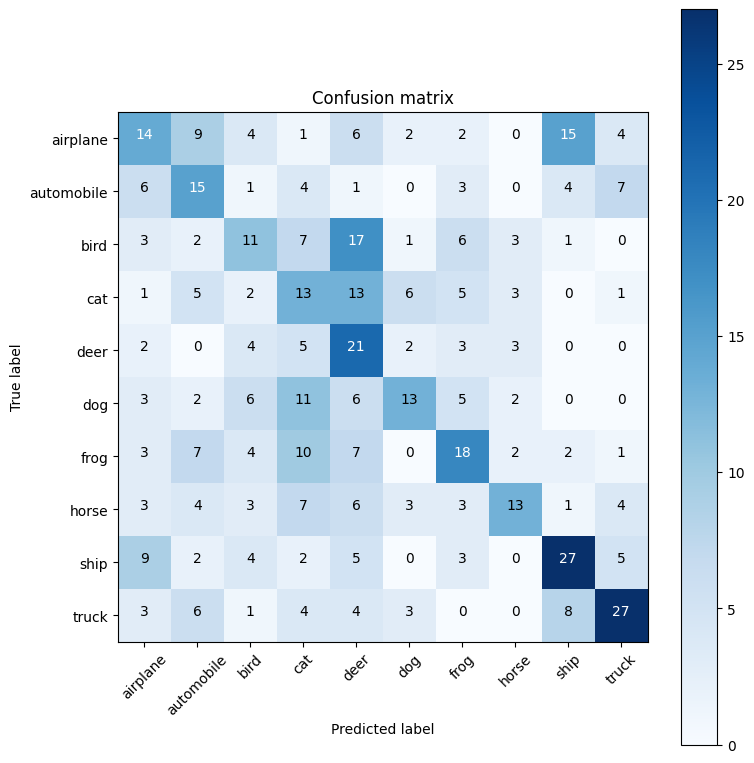

['/content/drive/MyDrive/models/svm_resnet50_features.joblib']

In [ ]:
# solution
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score

svm = GridSearchCV(SVC(), {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']})
svm.fit(dl_feature_descriptors, np.argmax(y_train_stratified, axis=1))
print(svm.best_params_)

x_test_small = np.array([transform.resize(img, (224, 224, 3), preserve_range=True, anti_aliasing=True) for img in x_test[:500]])
y_pred_svm = svm.predict(extract.predict(preprocess_input(x_test_small * 255), batch_size=32))
print('SVM test accuracy:', accuracy_score(y_test_labels[:500], y_pred_svm))
plot_confusion_matrix(y_test_labels[:500], y_pred_svm)
import joblib
joblib.dump(svm.best_estimator_, os.path.join(MODELS_DIR, "svm_resnet50_features.joblib"))

# Feature Visualizations

In order to visualize the features of a higher dimension data, t-SNE is used. t-SNE converts the affinities of the data points to probabilities. It recreates the probability distribution in a low-dimensional space. It is very helpful in visualizing features of different layers in a neural network.

You can find more information about t-SNE [here](https://scikit-learn.org/stable/modules/manifold.html#t-distributed-stochastic-neighbor-embedding-t-sne)

*    Use TSNE to visualize the features extracted in the previous exercise.
    *    Hint: TSNE function is available in the *sklearn.manifold* package.

[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 1500 samples in 0.007s...
[t-SNE] Computed neighbors for 1500 samples in 0.132s...
[t-SNE] Computed conditional probabilities for sample 1000 / 1500
[t-SNE] Computed conditional probabilities for sample 1500 / 1500
[t-SNE] Mean sigma: 8.245540
[t-SNE] KL divergence after 250 iterations with early exaggeration: 71.742889
[t-SNE] KL divergence after 1000 iterations: 1.533092


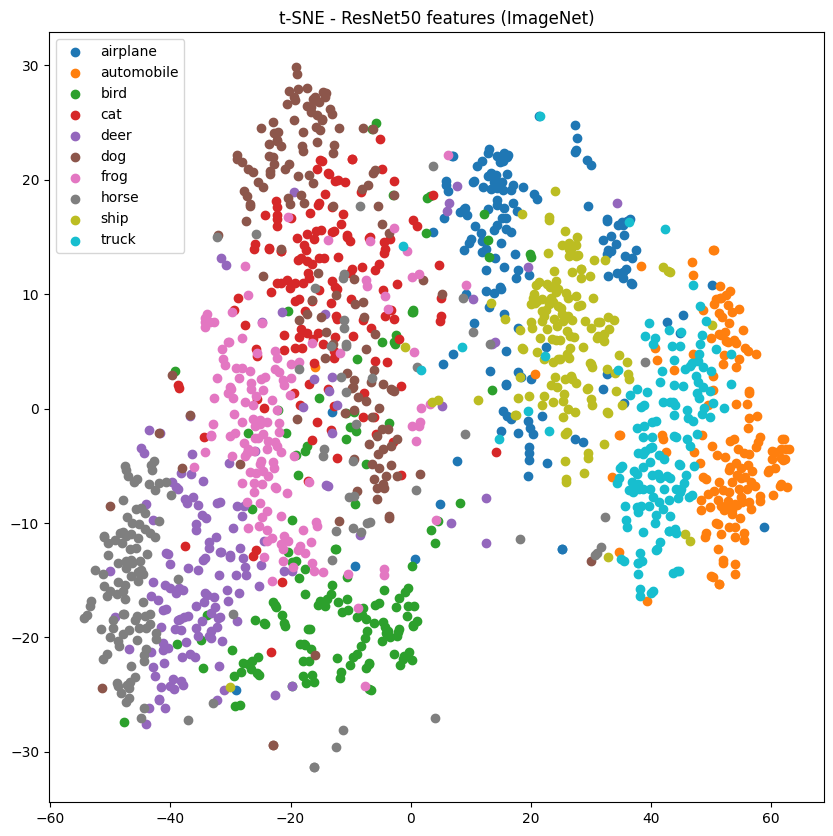

In [12]:
# solution
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

tsne = TSNE(n_components=2, verbose=1, perplexity=30, max_iter=1000)
tsne_results = tsne.fit_transform(PCA(n_components=50).fit_transform(dl_feature_descriptors))  # PCA first removes noise

plt.figure(figsize=(10, 10))
for cl in range(10):
  plt.scatter(tsne_results[np.where(np.argmax(y_train_stratified, axis=1) == cl)][:, 0],
              tsne_results[np.where(np.argmax(y_train_stratified, axis=1) == cl)][:, 1],
              label=CLASS_NAMES[cl])
plt.legend()
plt.title("t-SNE - ResNet50 features (ImageNet)")
plt.show()


In [16]:
vgg16 = keras.models.load_model(os.path.join(MODELS_DIR, "vgg16_cifar10.keras"), compile=False)

32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step
[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 1000 samples in 0.001s...
[t-SNE] Computed neighbors for 1000 samples in 0.121s...
[t-SNE] Computed conditional probabilities for sample 1000 / 1000
[t-SNE] Mean sigma: 9.644168
[t-SNE] KL divergence after 250 iterations with early exaggeration: 61.704922
[t-SNE] KL divergence after 1000 iterations: 0.778124


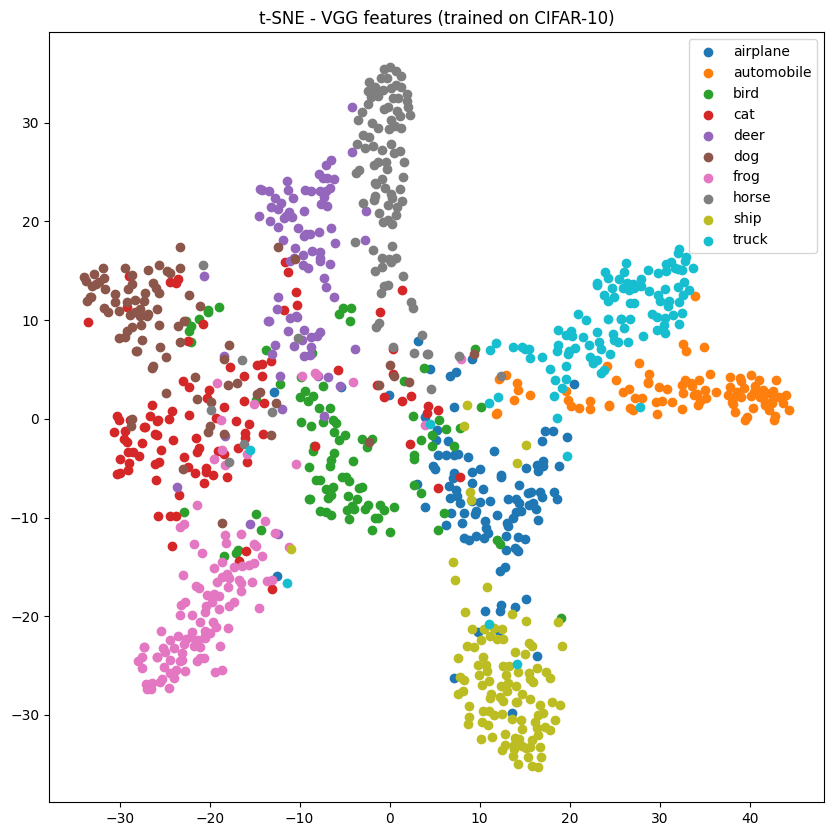

In [17]:
# t-SNE of the features learned by our VGG on CIFAR-10 (Dense(128) layer), to compare with ResNet50/ImageNet
vgg_extract = keras.Model(vgg16.inputs, vgg16.layers[-3].output)
vgg_feats = vgg_extract.predict(x_test[:1000])
vgg_tsne = TSNE(n_components=2, verbose=1, perplexity=30, max_iter=1000).fit_transform(PCA(n_components=50).fit_transform(vgg_feats))

plt.figure(figsize=(10, 10))
for cl in range(10):
  plt.scatter(vgg_tsne[y_test_labels[:1000] == cl, 0], vgg_tsne[y_test_labels[:1000] == cl, 1], label=CLASS_NAMES[cl])
plt.legend()
plt.title("t-SNE - VGG features (trained on CIFAR-10)")
plt.show()

*    Why is feature visualization helpful?